# Pumped storage: an average profile by hour of day

**Question:** Group pumped storage by hour of day, calculate the mean, plot a
curve, and discuss its shape.

**Learning goal:** Understand how the choice of variable, clock time, missing-value
handling, and grouping determines the question your plot answers. The main result
is a curve with 24 mean values, pooling available readings from 2015–2018.

Complete Steps 1–4 for the assignment. Steps 5–6 show how to check whether an
average hides variation across observations or years. The source CSV is read
without modification. Requirements: pandas, NumPy, Matplotlib, and IPython.

This is a mean **intraday profile**, not a histogram or a chronological sequence
of all hours. A peaked curve here is not evidence of a normal distribution.


## 1. Select the variable by meaning, not just by its name

First find the columns that mention pumped storage and count their missing values.
The file contains an `aggregated` column with no observations and a `consumption`
column with usable values. We therefore analyze **electricity consumed for pumping**.
Even though the name starts with `generation`, the suffix `consumption` matters.

If the intended question were specifically about electricity generated by pumped
storage, this file's entirely missing aggregated column could not answer it.
Missing generation values are not evidence of zero generation. Do not substitute
another hydro column without verifying its definition.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

path = Path('/Users/jiongwu/Downloads/archive/energy_dataset.csv')
df = pd.read_csv(path)

pumped_columns = [c for c in df.columns if 'pumped storage' in c]
column_check = pd.DataFrame({
    'valid': df[pumped_columns].count(),
    'missing': df[pumped_columns].isna().sum(),
})
display(column_check)

column = 'generation hydro pumped storage consumption'


,valid,missing
generation hydro pumped storage aggregated,0,35064
generation hydro pumped storage consumption,35045,19


## 2. Preserve the source's local clock and check the records

For this question, 04:00 means the local clock time written in the source.
The timestamp strings contain both `+01:00` and `+02:00` offsets. Extract their
date and clock portion before any UTC conversion:

- `.str.slice(0, 19)` keeps the first 19 characters, such as `2015-01-01 04:00:00`.
- `pd.to_datetime(...)` converts that text into datetime values.
- `.dt.hour` extracts an integer from 0 to 23 for each row.

This timezone-free local timestamp is a grouping label, not a unique elapsed-time
identifier. Use a separate timezone-aware UTC timestamp to check chronological
duplicates and gaps. Extracting `.dt.hour` from UTC would answer a different question.

The coverage checks below pass for this supplied file. If they fail for another
dataset, investigate before assuming all hourly intervals are represented.


In [2]:
df['local_time'] = pd.to_datetime(df['time'].str.slice(0, 19))
df['hour'] = df['local_time'].dt.hour
df['time_utc'] = pd.to_datetime(df['time'], utc=True)

assert df['time_utc'].notna().all(), 'Investigate missing timestamps.'
assert not df['time_utc'].duplicated().any(), 'Investigate duplicate instants.'
utc_times = pd.DatetimeIndex(df['time_utc'].sort_values())
expected = pd.date_range(utc_times.min(), utc_times.max(), freq='h')
assert utc_times.equals(expected), 'Investigate missing hourly timestamps.'

values = df[column]
quality = pd.Series({
    'rows': len(df),
    'valid_values': values.count(),
    'missing_values': values.isna().sum(),
    'recorded_zeros': values.eq(0).sum(),
    'negative_values': values.lt(0).sum(),
})
display(quality.to_frame('count'))
display(df[['time', 'local_time', 'hour', column]].head())
print(f'Missing readings: {values.isna().mean():.4%}')
print(f'Zero share of valid readings: {values.eq(0).sum() / values.count():.2%}')


,count
rows,35064
valid_values,35045
missing_values,19
recorded_zeros,12607
negative_values,0


,time,local_time,hour,generation hydro pumped storage consumption
0,2015-01-01 00:00:00+01:00,2015-01-01 00:00:00,0,863.0
1,2015-01-01 01:00:00+01:00,2015-01-01 01:00:00,1,920.0
2,2015-01-01 02:00:00+01:00,2015-01-01 02:00:00,2,1164.0
3,2015-01-01 03:00:00+01:00,2015-01-01 03:00:00,3,1503.0
4,2015-01-01 04:00:00+01:00,2015-01-01 04:00:00,4,1826.0


Missing readings: 0.0542%
Zero share of valid readings: 35.97%


There are **19 missing readings** and **12,607 recorded zeros** among 35,064 rows.
Keep zeros in the mean: a recorded zero can indicate no pumping at that time.
Treat NaN as unknown, not as inactivity. The observed values contain no negatives.
Missingness is small (about 0.054%), but its size alone does not prove it is unbiased.

For example, observations `[0, 100, NaN]` have a valid-observation mean of 50.
Replacing NaN with zero gives 33.33; removing zeros gives 100. These operations
change the question. No filling, interpolation, or zero filtering is needed here.


## 3. Group observations into 24 clock-hour categories

The core operation is `df.groupby('hour')[column].mean()`.

1. `groupby('hour')` puts all rows labeled 0 together, all rows labeled 1 together,
   and so on, across all dates and years.
2. `[column]` selects the quantity to summarize.
3. `.mean()` averages the non-missing readings in each group, including zeros.

For an hour $h$, the result is $\bar{x}_h = \sum_{i \in I_h} x_i / n_h$,
where $I_h$ contains valid observations at that clock hour and $n_h$ is their count.
It is an average hourly reading, not a daily total.

Use `.agg()` to request several summaries at once. `count` counts non-missing
values; `size` counts all rows, including missing values. `.reindex(range(24))`
keeps hours ordered from 0 to 23 and exposes an absent group as NaN.


In [3]:
hour_groups = df.groupby('hour')[column]

# The one-line answer to the grouping part of the question:
hourly_mean = hour_groups.mean().reindex(range(24))

# An expanded table helps us check and interpret that answer.
hourly = hour_groups.agg(
    mean='mean',
    median='median',
    n_valid='count',
    n_rows='size',
).reindex(range(24))
hourly['n_missing'] = hourly['n_rows'] - hourly['n_valid']

display(hourly.round(2))
peak_hour = int(hourly_mean.idxmax())
low_hour = int(hourly_mean.idxmin())
print(f'Highest mean: {peak_hour:02d}:00 = {hourly_mean.loc[peak_hour]:,.2f}')
print(f'Lowest mean:  {low_hour:02d}:00 = {hourly_mean.loc[low_hour]:,.2f}')

# Verify the 04:00 result by selecting that group explicitly.
four_am = df.loc[df['hour'].eq(4), column]
print(f'04:00 manual check: {four_am.sum():,.0f} / {four_am.count():,}'
      f' = {four_am.mean():,.2f}')


,mean,median,n_valid,n_rows,n_missing
hour,,,,,
0,434.62,205.0,1461,1461,0
1,762.37,494.0,1461,1461,0
2,1085.82,805.0,1461,1461,0
3,1302.28,1024.5,1460,1461,1
4,1384.48,1102.0,1461,1461,0
5,1278.29,1002.0,1461,1461,0
6,869.54,524.0,1461,1461,0
7,535.51,111.0,1461,1461,0
8,389.75,1.0,1461,1461,0


Highest mean: 04:00 = 1,384.48
Lowest mean:  21:00 = 55.44
04:00 manual check: 2,022,718 / 1,461 = 1,384.48


Each hour has 1,457–1,461 valid readings. The average uses each observed hourly
record once. When source clocks repeat an hour after an offset change, both
records belong to that local-hour group; skipped local hours contribute no record.
This is not a procedure that forces exactly one observation per date and clock hour.

Unlike the previous daily-total exercise, one missing reading does **not** require
discarding every other hour of that day for this available-observation mean.
The target is different: compare clock-hour groups, rather than calculate complete
daily totals. An observed-row count is not a general guarantee of expected coverage;
the preceding UTC continuity check supports this dataset's coverage assessment.

`resample('h').mean()` would retain separate chronological hourly bins. It does
not combine 04:00 across different days. `groupby('hour').sum()` would calculate
totals accumulated across the sample instead of the requested mean.


## 4. Plot the mean curve and describe what it shows

The horizontal axis is source local clock hour. The vertical axis is mean pumping
consumption in the original file units. The CSV itself does not define physical
units, so do not label these values MW or MWh without checking source metadata.
The markers are the 24 calculated means; connecting lines help show their pattern.


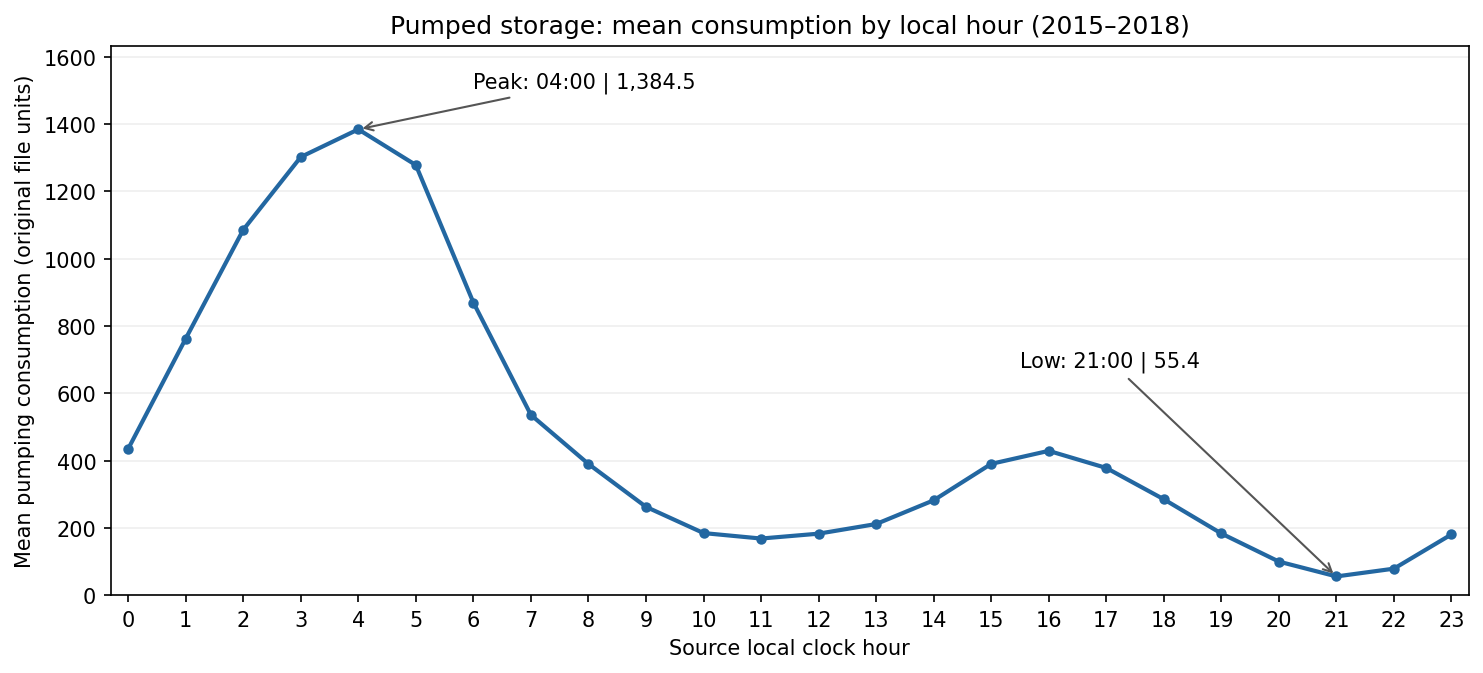

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(hourly_mean.index, hourly_mean.values,
        color='#2367A1', marker='o', markersize=4, linewidth=2)
ax.set(title='Pumped storage: mean consumption by local hour (2015–2018)',
       xlabel='Source local clock hour',
       ylabel='Mean pumping consumption (original file units)',
       xlim=(-0.3, 23.3), ylim=(0, hourly_mean.max() * 1.18))
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.annotate(f'Peak: {peak_hour:02d}:00 | {hourly_mean.loc[peak_hour]:,.1f}',
            xy=(peak_hour, hourly_mean.loc[peak_hour]), xytext=(6, 1510),
            arrowprops={'arrowstyle': '->', 'color': '#555555'})
ax.annotate(f'Low: {low_hour:02d}:00 | {hourly_mean.loc[low_hour]:,.1f}',
            xy=(low_hour, hourly_mean.loc[low_hour]), xytext=(15.5, 680),
            arrowprops={'arrowstyle': '->', 'color': '#555555'})
fig.tight_layout()
plt.show()


### Interpret in three layers: observation, explanation, limitation

**Observation.** Mean pumping consumption rises after midnight and peaks at 04:00
(1,384.48). It falls through the morning to a local low around 11:00 (168.09),
then shows a smaller afternoon hump around 16:00 (428.73). The overall minimum
is at 21:00 (55.44), followed by a late-evening rise.

**Plausible explanation.** Pumped storage uses electricity to lift water for later
generation. Pumping is often scheduled when electricity demand or prices are low.
The early-morning peak is consistent with that operating logic. This is a plausible
interpretation, not proof of the cause in this dataset. See the
[U.S. EIA explanation of hydropower](https://www.eia.gov/energyexplained/hydropower/).

**Limitation.** Low evening pumping consumption does not establish high evening
generation: these are different measurements. The available curve also cannot
identify why the afternoon hump occurs. To investigate, compare corresponding
load and price records and examine weekday/weekend or seasonal differences.

This figure averages many different dates. It does not describe every individual
day, show a long-term chronological trend, or establish a probability distribution.


## 5. Optional: does the mean describe a typical observation?

Compare the mean with the median and the 25th–75th percentile range at each hour.
The shaded band describes the spread of individual recorded values in each group;
it is **not** a confidence interval for the estimated mean.

Mean values can exceed medians when a subset of high observations pulls the average
upward. A positive mean also does not imply pumping on every date. Calculate the
zero proportion with a valid-value denominator; NaN must not be counted as zero.


,mean,median,q25,q75,zero_fraction
hour,,,,,
4,1384.475,1102.0,499.0,2138.00,0.034
11,168.094,0.0,0.0,97.00,0.561
16,428.726,77.5,0.0,551.25,0.365
21,55.436,0.0,0.0,1.00,0.672


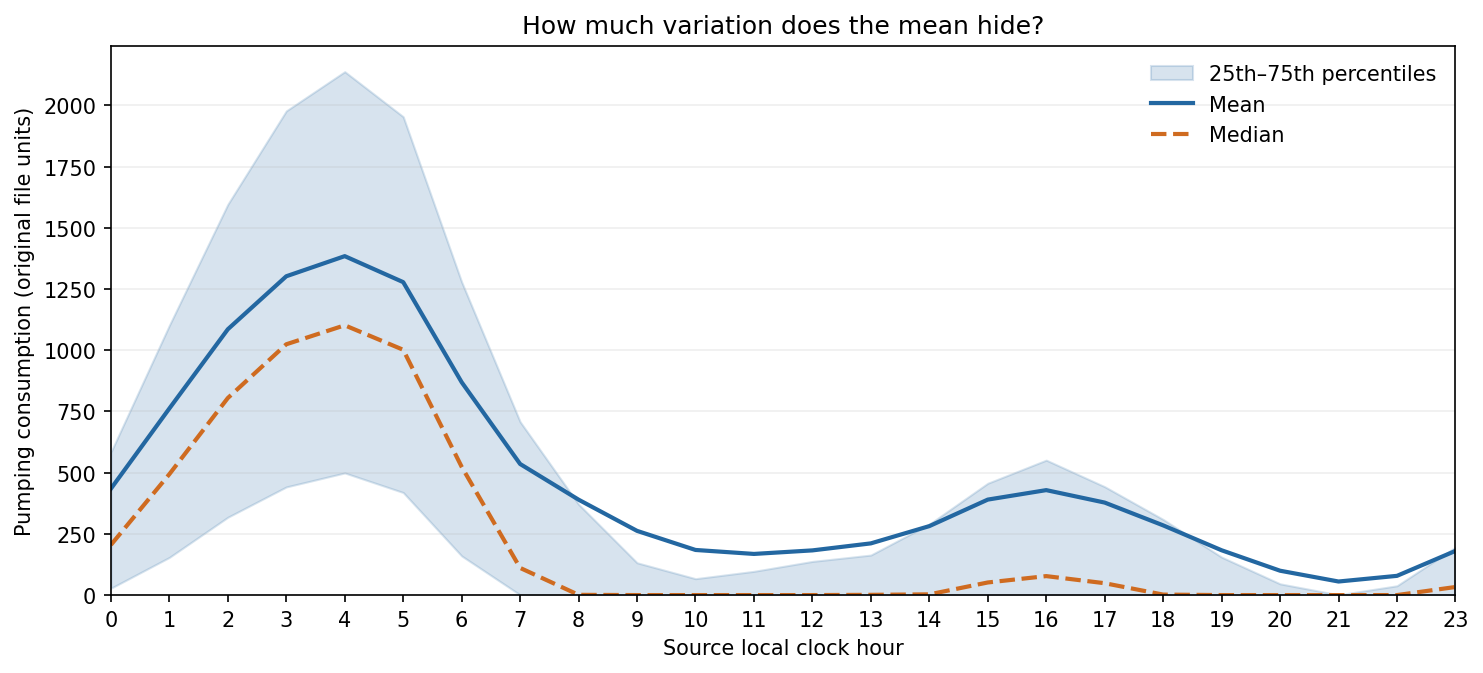

In [5]:
hourly['q25'] = hour_groups.quantile(0.25)
hourly['q75'] = hour_groups.quantile(0.75)

valid_rows = df.loc[df[column].notna()].copy()
valid_rows['is_zero'] = valid_rows[column].eq(0)
hourly['zero_fraction'] = valid_rows.groupby('hour')['is_zero'].mean()
display(hourly.loc[[4, 11, 16, 21],
                   ['mean', 'median', 'q25', 'q75', 'zero_fraction']].round(3))

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(hourly.index, hourly['q25'], hourly['q75'],
                alpha=0.18, color='#2367A1', label='25th–75th percentiles')
ax.plot(hourly.index, hourly['mean'], color='#2367A1', label='Mean', linewidth=2)
ax.plot(hourly.index, hourly['median'], color='#CF6B20',
        linestyle='--', label='Median', linewidth=2)
ax.set(title='How much variation does the mean hide?',
       xlabel='Source local clock hour', ylabel='Pumping consumption (original file units)',
       xlim=(0, 23), ylim=(0, None))
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


At 04:00, the mean is about 1,384 and the median is 1,102. At 21:00, the mean is
about 55 but the median is zero. The profile therefore combines many zero or small
observations with some larger readings; it is not a schedule followed identically
every day. About 35.97% of all valid readings are zero.

Keep recorded zeros for this descriptive analysis. Separate evidence would be
needed to identify particular zeros as recording errors. Removing every zero
would instead estimate consumption conditional on a nonzero reading.


## 6. Optional: does pooling four years hide changes?

Group by both `hour` and `year`. `.unstack('year')` moves the year level of the
result into columns, producing a 24-row table with one column per year.
Each column is a separate intraday mean profile.


,peak_hour,peak_mean,lowest_hour
year,,,
2015,4,1601.95,21
2016,4,1535.00,21
2017,4,1245.20,21
2018,4,1155.34,21


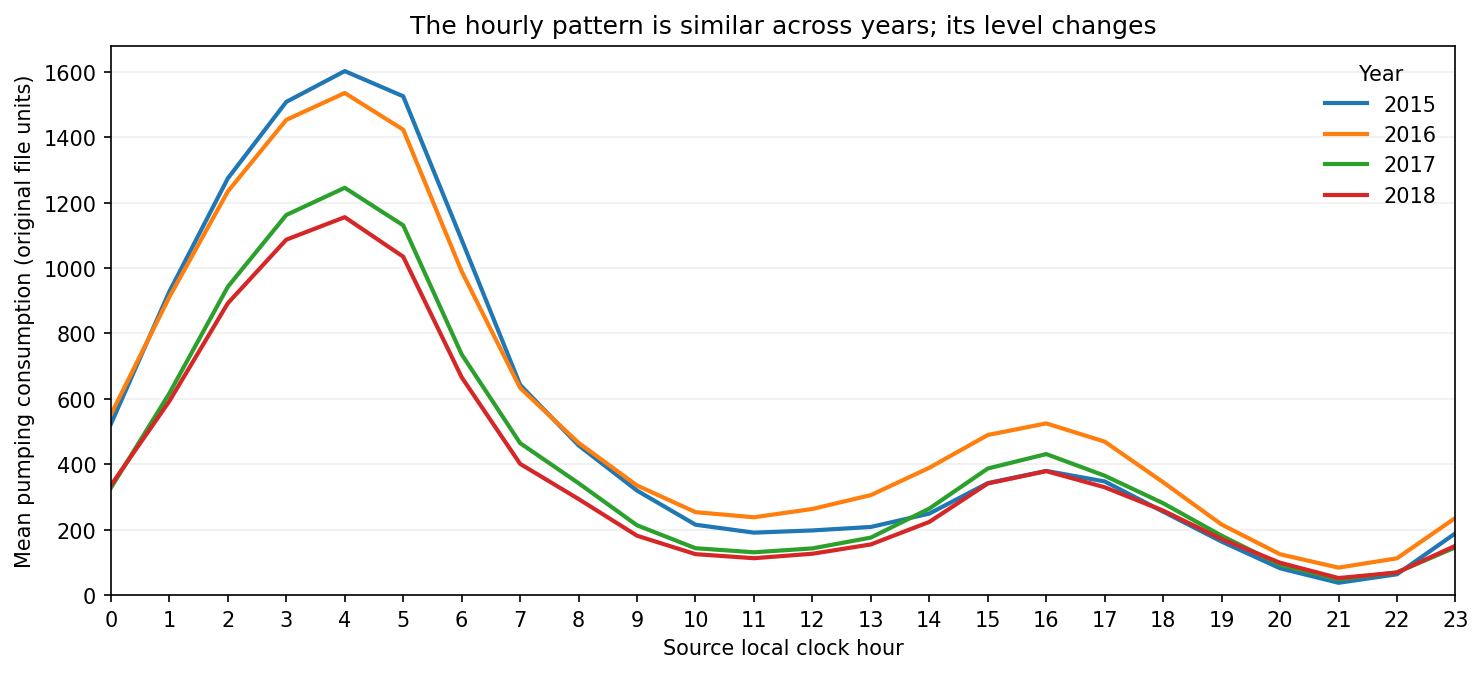

In [6]:
df['year'] = df['local_time'].dt.year
by_year = (
    df.groupby(['hour', 'year'])[column]
      .mean()
      .unstack('year')
      .reindex(range(24))
)

year_summary = pd.DataFrame({
    'peak_hour': by_year.idxmax(),
    'peak_mean': by_year.max(),
    'lowest_hour': by_year.idxmin(),
})
display(year_summary.round(2))

ax = by_year.plot(figsize=(10, 4.6), linewidth=2)
ax.set(title='The hourly pattern is similar across years; its level changes',
       xlabel='Source local clock hour', ylabel='Mean pumping consumption (original file units)',
       xlim=(0, 23), ylim=(0, None))
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.legend(title='Year', frameon=False)
plt.tight_layout()
plt.show()


In each of the four observed years, the maximum is at 04:00 and the minimum at
21:00. The 04:00 mean falls from about 1,602 in 2015 to 1,155 in 2018. This supports
the timing pattern within this sample, while showing that the overall average
hides changes in magnitude. It does not establish the cause or guarantee that
future years will follow the same pattern.

### A concise answer to the assignment

I analyzed `generation hydro pumped storage consumption`, because the other
pumped-storage field is entirely missing. I extracted source local clock hours,
grouped the valid hourly readings into 24 groups, and calculated their means while
retaining recorded zeros. Average pumping consumption peaks at 04:00 (1,384.48 in
original file units), declines during the morning, has a smaller hump near 16:00
(428.73), and reaches its minimum at 21:00 (55.44). The early-morning concentration
is consistent with pumping during lower-demand or lower-price periods, although
the profile alone does not prove that explanation. This is a mean consumption
profile, not a generation curve or a probability distribution. Differences between
the mean and median, as well as between years, show why a pooled average should
not be interpreted as the behavior of every day.

### Practice before moving on

1. Change `mean()` to `median()`. Which hours change most? Explain why.
2. Use `.dt.dayofweek` (Monday=0, Sunday=6) to distinguish weekdays and weekends.
   Group by both day type and hour. Does the morning decline occur at the same time?
3. Explain why filling missing values with zero, filtering out recorded zeros,
   and grouping UTC hours would each change what your result means.
